# Øvelser: Figurer der forklarer

**Social Data Science 1: lektion 4**

Data er det samme tweet-datasæt som i lektion 3.

**Sådan arbejder I:**

- Kør cellerne ovenfra og ned.
- **Beskriv figuren, før I retter den.** Hvad ser I faktisk?
- Læs advarsler. Plotnine fortæller, hvor mange observationer den ikke har tegnet.
- Der er sjældent ét rigtigt svar. Der er svar, I kan begrunde.


---

## Data

Kør cellen. Det er de samme fire linjer som på slidesene.


In [1]:
%pip install pandas
%pip install plotnine

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [5]:
import pandas as pd
from plotnine import *

url = "https://raw.githubusercontent.com/jeppeFQ/sds1/main/data/data_tweets_2016_kilde_a.csv"
tweets = pd.read_csv(url)

tweets["dato"]        = pd.to_datetime(tweets["date"])
tweets["maaned"]      = tweets["dato"].dt.month
tweets["har_hashtag"] = tweets["hashtags"].notna()
tweets["antal_ord"]   = tweets["content"].str.split().str.len()

print(tweets.shape)


(3945, 11)


---

## Opgave 1: Basis-figuren

**Trin 1: kør cellen.** Tre komponenter: data, mapping, geom.


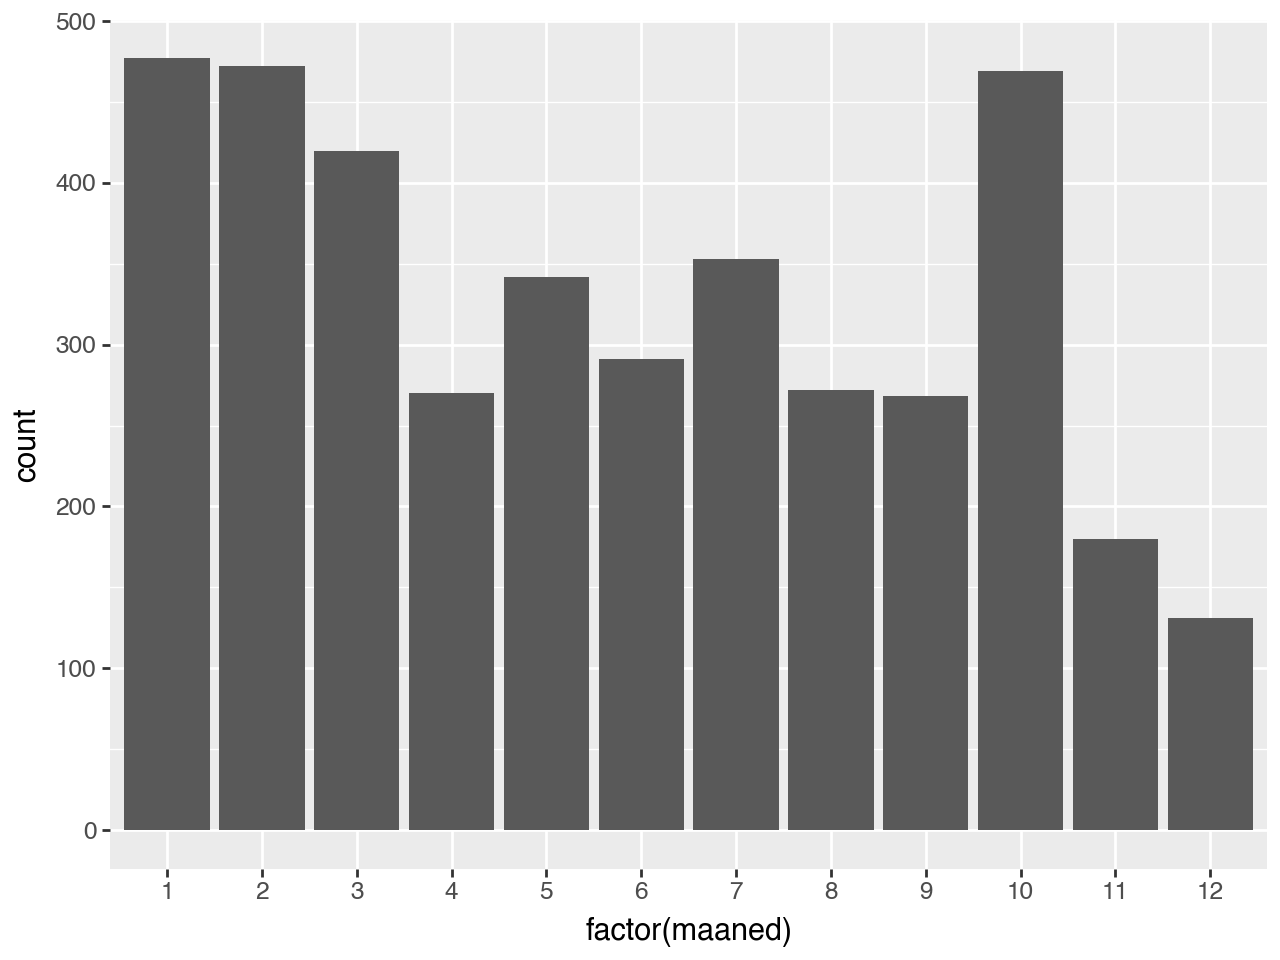

In [6]:
(ggplot(tweets, aes(x="factor(maaned)")) + geom_bar()).show()

**Trin 2: gør den læsbar.**

Figuren har ingen titel, og akserne hedder `factor(maaned)` og `count`. Det er
kolonnenavne, ikke akseetiketter.

Tilføj `+ labs(...)` med `title`, `x` og `y`. Prøv også `+ theme_minimal()`.

*Hint:* argumenterne skal stå i anførselstegn: `labs(title="...")`.


In [ ]:
# Din kode her
(ggplot(tweets, aes(x="factor(maaned)"))
 + geom_bar()
 + labs(title="Antal tweets per måned",
        x="Måned", y="Antal tweets")
 + theme_minimal()).show()

In [ ]:
(ggplot(tweets, aes(x="factor(maaned)"))
 + geom_bar()
 + labs(title="Aktiviteten faldt gennem efteråret",
        subtitle="Antal tweets per måned, 2016",
        x="Måned", y="Antal tweets")
 + theme_minimal()).show()

---

## Opgave 2: Inde i eller uden for `aes()`

**Trin 1: en fast farve.** Kør cellen.


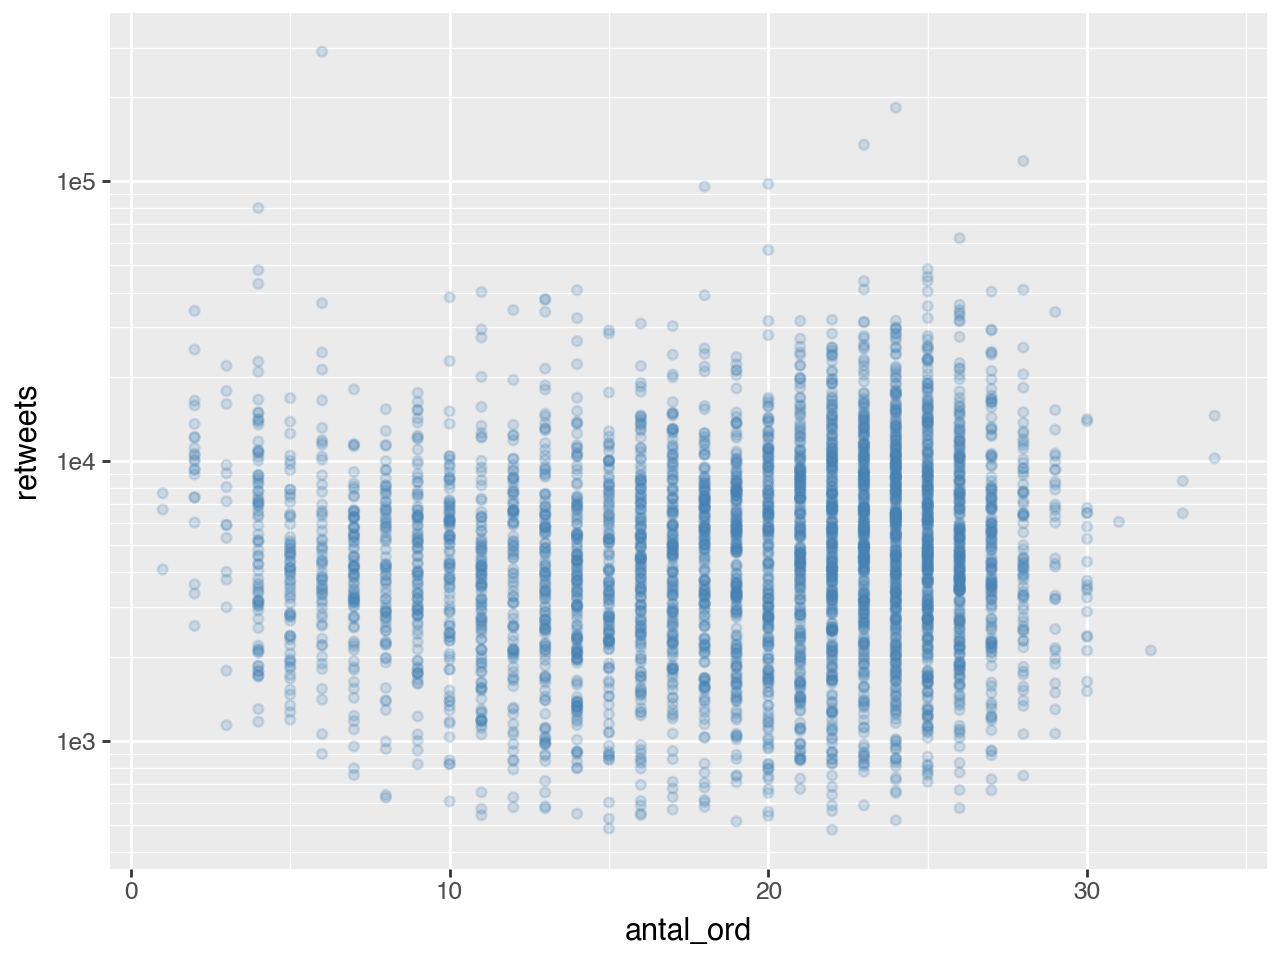

In [7]:
(ggplot(tweets, aes(x="antal_ord", y="retweets"))
 + geom_point(color="steelblue", alpha=0.2)
 + scale_y_log10()).show()



**Trin 2: en variabel som farve.**

Flyt farven ind i `aes()`, og lad den bestemmes af `har_hashtag` i stedet for at være
fast.

Der sker to ting. Den ene er, at punkterne får to farver. Hvad er den anden?


In [ ]:
# Din kode her
(ggplot(tweets, aes(x="antal_ord", y="retweets", color="har_hashtag"))
 + geom_point(alpha=0.2)
 + scale_y_log10()
 + labs(color="Har hashtag")).show()



**Trin 3: fejlen.**

Kør cellen herunder. Den er skrevet forkert med vilje.

Hvilken farve bliver punkterne? Og hvad står der i forklaringsboksen?


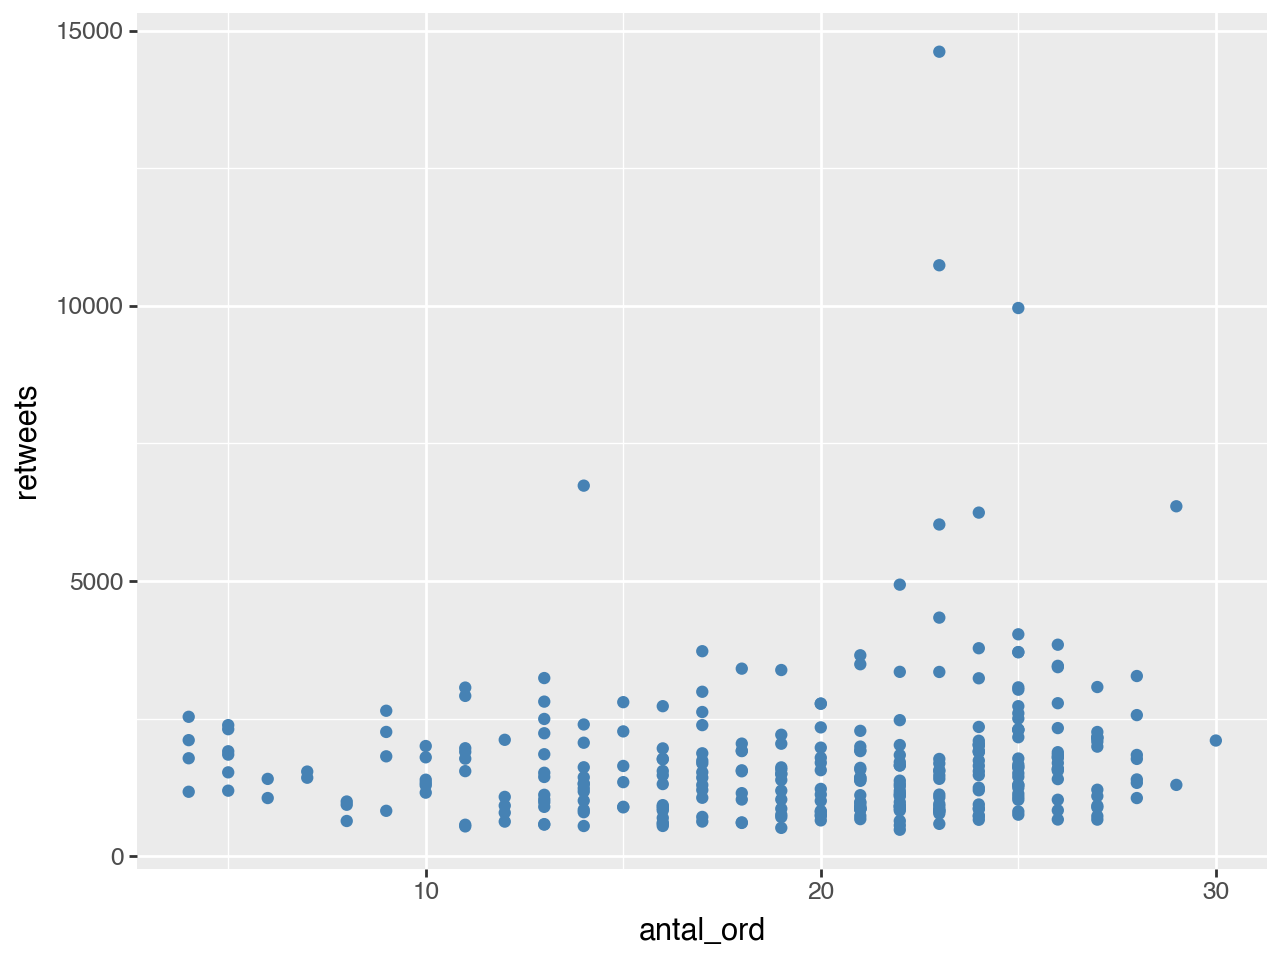

In [9]:
(ggplot(tweets.head(300), aes(x="antal_ord", y="retweets", color="'steelblue'"))
 + geom_point()).show()


### 2.4 Til diskussion

1. Formulér reglen for, hvad der skal ind i `aes()`, og hvad der skal udenfor.
2. Hvordan ville I opdage fejlen i trin 3, hvis I ikke vidste, den var der?


---

## Opgave 3: Manipulér med vilje

Her skal I lave to figurer af de samme tal: én der gør forskellen så **lille** som
muligt, og én der gør den så **stor** som muligt.

**Trin 1: beregn tallene.** Kør cellen.


In [8]:
gns = tweets.groupby("maaned")["retweets"].mean().reset_index()
print(gns.round(0))


    maaned  retweets
0        1    1784.0
1        2    2741.0
2        3    4564.0
3        4    4018.0
4        5    4544.0
5        6    6005.0
6        7    8259.0
7        8    7474.0
8        9    7875.0
9       10   10120.0
10      11   18990.0
11      12   15119.0


**Trin 2: den mindst dramatiske version.**

Lav et søjlediagram af `gns`. Lad y-aksen starte i nul, som den gør af sig selv.


In [ ]:
# Din kode her
(ggplot(gns, aes(x="factor(maaned)", y="retweets"))
 + geom_col()
 + labs(title="Version A: fra nul",
        x="Måned", y="Gns. retweets")).show()


**Trin 3: den mest dramatiske version.**

Samme data, samme geom. Tilføj `+ coord_cartesian(ylim=(..., ...))` og vælg grænser,
der gør forskellen mellem månederne så stor som muligt.

Skriv én sætning om, hvad hver af de to figurer "siger".


In [ ]:
# Din kode her
(ggplot(gns, aes(x="factor(maaned)", y="retweets"))
 + geom_col()
 + coord_cartesian(ylim=(1500, 19000))
 + labs(title="Version B: zoomet",
        x="Måned", y="Gns. retweets")).show()


**Trin 4: sæt ord på**

Er figuren fra trin 3 grim, dårlig eller forkert? Begrund det.

*Grim* er et æstetisk problem. *Dårlig* er et perceptionsproblem. *Forkert* er et
matematisk problem.


*Jeres svar her:*




**Trin 5: zoom "lovligt".**

I må gerne zoome. I skal bare bruge en geometri, der kun koder værdien ét sted.

Lav samme zoom som i trin 3, men med `geom_point(size=4)` i stedet for `geom_col()`.

Hvorfor er det her i orden, når trin 3 ikke var?


In [ ]:
# Din kode her
(ggplot(gns, aes(x="factor(maaned)", y="retweets"))
 + geom_point(size=4)
 + coord_cartesian(ylim=(1500, 19000))
 + labs(title="Punkter tåler et zoom",
        x="Måned", y="Gns. retweets")).show()


---

## Opgave 4: Zoom eller slet?

Der findes to måder at begrænse en akse på, og de gør ikke det samme.

**Trin 1: kør cellen, og læs advarslen under/over figuren.**


/Users/jeppefl/Library/r-miniconda/lib/python3.10/site-packages/plotnine/layer.py:358: PlotnineWarning: position_stack : Removed 5 rows containing missing values.
/Users/jeppefl/Library/r-miniconda/lib/python3.10/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_col : Removed 7 rows containing missing values.


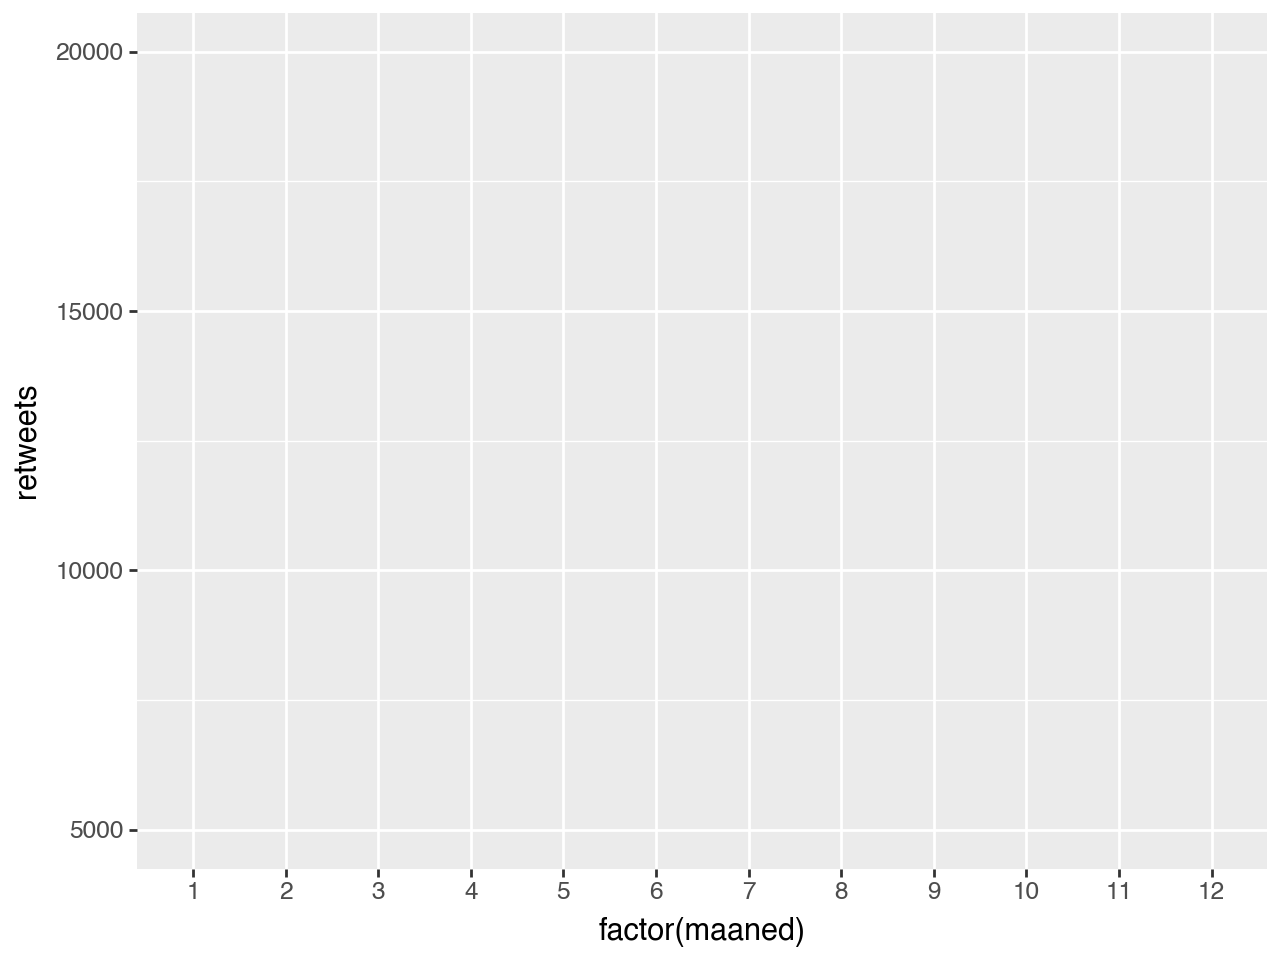

In [9]:
(ggplot(gns, aes(x="factor(maaned)", y="retweets"))
 + geom_col()
 + scale_y_continuous(limits=(5000, 20000))).show()



**Trin 2: sammenlign.**

Byt `scale_y_continuous(limits=...)` ud med `coord_cartesian(ylim=...)` og de samme
to tal. Kør igen.

Hvad er forskellen på de to figurer? Og hvad står der i advarslen i trin 1?


In [ ]:
# Din kode her
(ggplot(gns, aes(x="factor(maaned)", y="retweets"))
 + geom_col()
 + coord_cartesian(ylim=(5000, 20000))
 + labs(title="coord_cartesian(ylim=...)")).show()


### 4.3 Til diskussion

1. Hvor mange observationer forsvandt i trin 1? 
2. Hvornår ville I kunne komme til at bruge den forkerte af de to uden at opdage det?


---

## Opgave 5: Absolut eller relativ

**Trin 1: byg tabellen.** En tweet regnes som "stor", hvis den har over 10.000
retweets.


In [10]:
tweets["stor"] = tweets["retweets"] > 10000

stor = (tweets.groupby("maaned")
        .agg(antal_store=("stor", "sum"), i_alt=("id", "size"))
        .reset_index())
stor["andel"] = stor["antal_store"] / stor["i_alt"]

print(stor)

    maaned  antal_store  i_alt     andel
0        1            2    477  0.004193
1        2            6    472  0.012712
2        3           20    420  0.047619
3        4            4    270  0.014815
4        5           12    342  0.035088
5        6           29    291  0.099656
6        7           85    353  0.240793
7        8           53    272  0.194853
8        9           56    268  0.208955
9       10          194    469  0.413646
10      11          113    180  0.627778
11      12           83    131  0.633588


**Trin 2: to figurer.**

Lav først et søjlediagram af `antal_store`. Lav derefter et af `andel`.

Gæt, før I kører: kommer de to figurer til at have samme rangorden af måneder?


In [ ]:
# Din kode her
# Absolutte tal
(ggplot(stor, aes(x="factor(maaned)", y="antal_store"))
 + geom_col()
 + labs(title="Antal tweets med over 10.000 retweets",
        x="Måned", y="Antal")).show()

# Andele
(ggplot(stor, aes(x="factor(maaned)", y="andel"))
 + geom_col()
 + labs(title="Andel af månedens tweets med over 10.000 retweets",
        x="Måned", y="Andel")).show()


### 5.3 Til diskussion

1. Hvilke måneder skifter plads mellem de to figurer?
2. Hvilken af de to ville I sætte i en opgave, og hvad ville der stå i figurteksten?
3. Er den ene af dem forkert?


---

## Opgave 6: Vis fordelingen

**Trin 1: gennemsnittet alene.** Kør cellen.


In [11]:
print(tweets["retweets"].describe().round(0))


count      3945.0
mean       6502.0
std        8667.0
min         482.0
25%        2552.0
50%        4593.0
75%        7901.0
max      289872.0
Name: retweets, dtype: float64


**Trin 2: histogram.**

Lav et histogram over `retweets` med `geom_histogram(bins=30)`.

Kan I se noget? Hvorfor ikke?


In [ ]:
# Din kode her



**Trin 3: log-skala.**

Tilføj `+ scale_x_log10()`. Kør igen.

Hvad kan I se nu, som I ikke kunne se før?


In [ ]:
# Din kode her



**Trin 4: antal intervaller.**

Prøv den samme figur med `bins=5`, `bins=30` og `bins=200`.

`bins` er ikke pynt: det er et argument til den beregning, `geom_histogram` laver,
før den tegner. Hvilken af de tre viser fordelingen mest ærligt?


In [ ]:
# Din kode her



**Trin 5: tolv fordelinger på én figur.**

Lav et boxplot med `factor(maaned)` på x-aksen og `retweets` på y-aksen. Husk
log-skalaen.

Sammenlign med søjlediagrammet fra opgave 3. Hvad kan I se her, som gennemsnittet
skjulte?


In [ ]:
# Din kode her



---

## Opgave 7: Byg en figur op i lag

Her bygger I én figur i fire skridt. Gem den i variablen `p` undervejs, så I kan
lægge til uden at skrive det hele forfra.

**Trin 1: den rå base.**


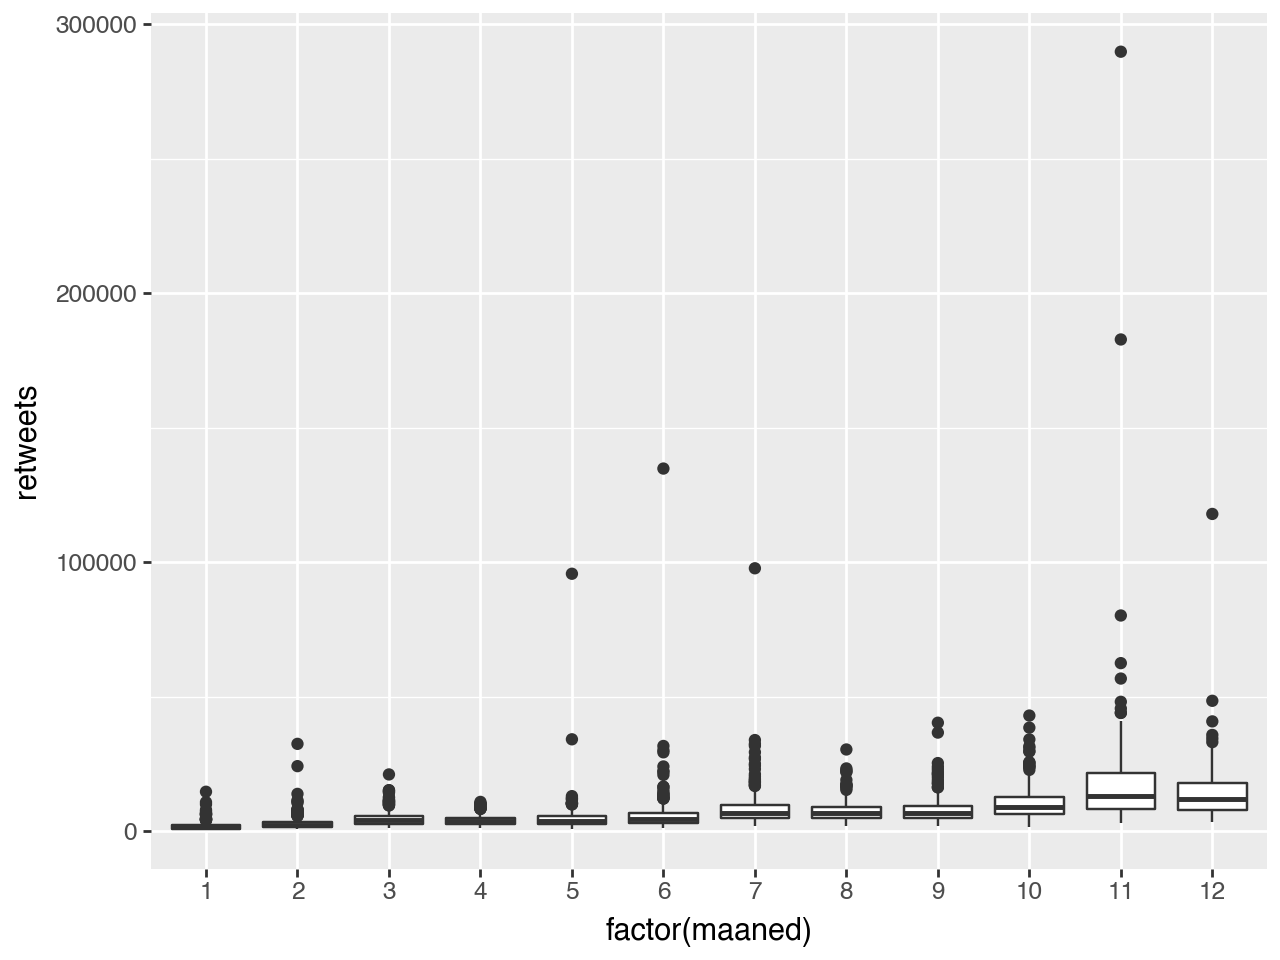

In [12]:
p = (ggplot(tweets, aes(x="factor(maaned)", y="retweets"))
     + geom_boxplot())
p.show()


**Trin 2: ret skalaen**, så fordelingen bliver læsbar.


In [ ]:
# p = p + ...

# Din kode her


**Trin 3: vælg et tema.** Prøv `theme_minimal()`, `theme_bw()` og `theme_classic()`.


In [ ]:
# Din kode her



**Trin 4: gør den færdig.**

Tilføj `labs()` med:

- `title`: et udsagn om, hvad man skal lægge mærke til
- `subtitle`: hvilket udsnit af data ser vi?
- `x` og `y`: hvad står der på akserne, og i hvilken enhed?
- `caption`: hvor kommer data fra?

Vis den til en anden gruppe **uden at sige noget**. Forstod de den?


In [ ]:
# Din kode her

